In [14]:
import numpy as np
data = np.load("/home/hamzeh/Documents/MEAOW_project/hypothesis_4/h4_epoch_spectra_mean.npz")
print(data.files)

['epoch_ids', 'freqs', 'original', 'flattened']


In [15]:
freqs = (data["freqs"])
original = data["original"]        # shape (n_epochs, n_freqs)
flattened = data["flattened"]
epoch_ids = data["epoch_ids"]

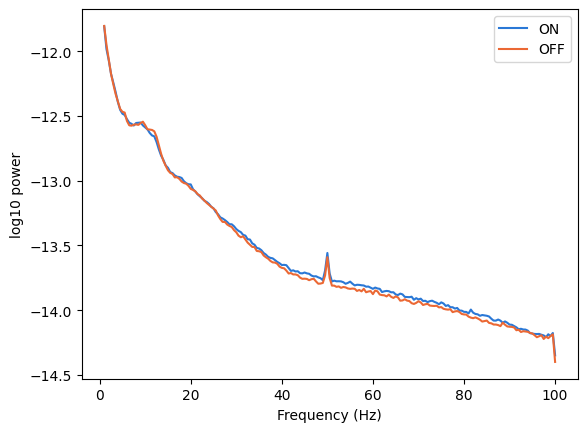

In [17]:
import matplotlib.pyplot as plt
# epoch_ids alone don't carry condition -- that lives in h4_epoch_level.csv.
# Easiest path: load that CSV and match on epoch_id.
import pandas as pd
epochs_csv = pd.read_csv("/home/hamzeh/Documents/MEAOW_project/hypothesis_4/h4_epoch_level.csv")   # add the _mean tag if AVERAGING=mean
lookup = dict(zip(epochs_csv["epoch_id"], epochs_csv["condition"]))

on_mask = np.array([lookup.get(e) == "ON" for e in epoch_ids])
off_mask = np.array([lookup.get(e) == "OFF" for e in epoch_ids])

on_avg = np.median(original[on_mask], axis=0)   # match AVERAGING in h4_config.py
off_avg = np.median(original[off_mask], axis=0)

plt.plot(freqs, on_avg, label="ON", color="#2a78d6")
plt.plot(freqs, off_avg, label="OFF", color="#eb6834")
plt.xlabel("Frequency (Hz)")
plt.ylabel("log10 power")
plt.legend()
plt.savefig("quick_check.png", dpi=200)

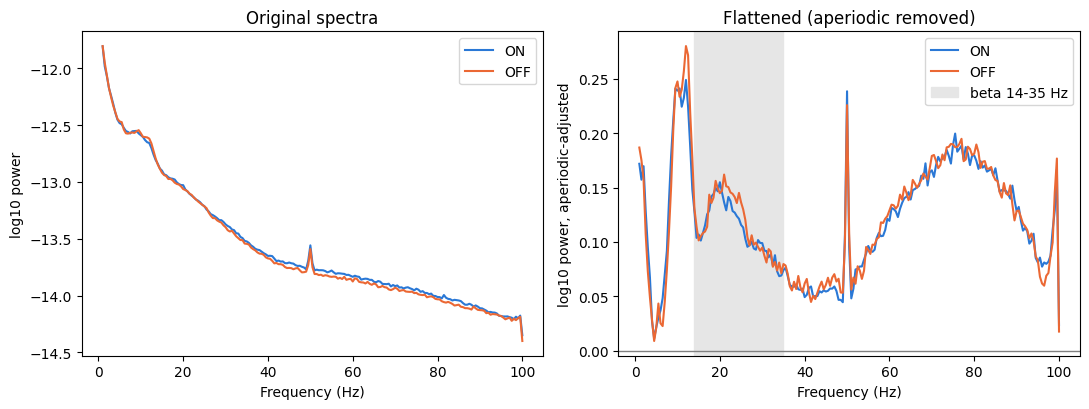

In [18]:
flattened = data["flattened"]      # (n_epochs, n_freqs), same shape/order as original

on_flat_avg = np.median(flattened[on_mask], axis=0)
off_flat_avg = np.median(flattened[off_mask], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].plot(freqs, on_avg, label="ON", color="#2a78d6")
axes[0].plot(freqs, off_avg, label="OFF", color="#eb6834")
axes[0].set_title("Original spectra")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("log10 power")
axes[0].legend()

axes[1].plot(freqs, on_flat_avg, label="ON", color="#2a78d6")
axes[1].plot(freqs, off_flat_avg, label="OFF", color="#eb6834")
axes[1].axhline(0, color="gray", lw=1)
axes[1].axvspan(14, 35, color="0.9", zorder=0, label="beta 14-35 Hz")
axes[1].set_title("Flattened (aperiodic removed)")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("log10 power, aperiodic-adjusted")
axes[1].legend()

fig.tight_layout()
fig.savefig("quick_check.png", dpi=200)